# Exploratory Data Analysis & Visualization
**Dataset:** Runner Automobile in a Market Point of View - Driver
**Input:** `clean_runner_automobile.csv` (produced by `EDA_preprocessing.ipynb`)

This notebook addresses the five tasks of the assignment: dataset description, column typing, EDA, visualisations, and insights.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 200)

df      = pd.read_csv("clean_runner_automobile.csv")
long_df = pd.read_csv("clean_runner_automobile_long.csv")

years          = [c for c in df.columns if c not in ('section','line_item')]
actual_years   = [c for c in years if c.endswith('A')]
forecast_years = [c for c in years if c.endswith('P')]
print("Wide-form:", df.shape, "| Long-form:", long_df.shape)
df.head()

Wide-form: (202, 15) | Long-form: (2626, 6)


,section,line_item,2018A,2019A,2020A,2021A,2022A,2023A,2024A,2025P,2026P,2027P,2028P,2029P,2030P
0,Revenue,Sales (Runner Automobiles PLC),4.201494e+09,4.324567e+09,3.911444e+09,3.790299e+09,3.427416e+09,2.877438e+09,4.687258e+09,5.734258e+09,7.095336e+09,8.850680e+09,1.110521e+10,1.399132e+10,1.769002e+10
1,Revenue,Credit business income,NaN,NaN,NaN,1.041583e+09,1.029734e+09,5.554609e+08,1.011445e+09,1.112589e+09,1.223848e+09,1.346233e+09,1.480856e+09,1.628942e+09,1.140259e+09
2,Revenue,YoY Growth of Credit business income,NaN,NaN,NaN,-1.140000e-02,-4.606000e-01,8.209000e-01,1.000000e-01,1.100000e+00,1.100000e+00,1.100000e+00,1.100000e+00,1.100000e+00,7.000000e-01
3,Revenue,Sales (Runner Motors Limited),5.759523e+09,6.325884e+09,6.070400e+09,6.403667e+09,6.649356e+09,4.103383e+09,3.975775e+09,4.291053e+09,4.685365e+09,5.151906e+09,5.673567e+09,6.280212e+09,6.961933e+09
4,Revenue,YoY Sales (Runner Motors Limited),9.830000e-02,-4.040000e-02,5.490000e-02,3.840000e-02,-3.829000e-01,-3.110000e-02,7.930000e-02,9.190000e-02,9.960000e-02,1.013000e-01,1.069000e-01,1.086000e-01,-1.000000e+00


## Task 1 - Explain the Dataset

| Field | Value |
|---|---|
| **Dataset name** | Runner Automobile in a Market Point of View - Driver |
| **Source** | Internal financial driver sheet for Runner Automobiles PLC (Bangladesh-listed automobile manufacturer). Equivalent data is published in the company annual reports on the Dhaka Stock Exchange. |
| **Purpose** | Provide a multi-year view of revenue, segment break-up, cost structure, taxes, retained earnings and working capital. The forward years are projections used for valuation / DCF work from a market analyst standpoint. |
| **Rows x columns** | 202 line items x 15 columns (1 section, 1 line-item label, 13 yearly value columns). |
| **Time span** | 2018A - 2024A (Actual) and 2025P - 2030P (Projected). |

**Description of features / columns**

- `section` - broad financial category each row belongs to (Revenue, Break-up of sales revenue by RAPLC, Break-up of sales revenue by RML, Cost of sales, Retained Earning).
- `line_item` - the specific accounting line (e.g. *Total Revenue*, *Depreciation*, *Trade Receivables*).
- `2018A ... 2024A` - historical actuals.
- `2025P ... 2030P` - forecast / projected values.

Each yearly column carries a numeric value that is either a monetary amount in BDT (Bangladeshi Taka), a count (e.g. *Number of Shares*), a population figure (millions), or a ratio / percentage (already converted to a fraction during preprocessing).

In [2]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("Sections:")
print(df['section'].value_counts())

Rows: 202 | Columns: 15
Sections:
section
Cost of sales                         114
Break-up of sales revenue by RAPLC     34
Retained Earning                       23
Revenue                                22
Break-up of sales revenue by RML        9
Name: count, dtype: int64


## Task 2 - Categorical vs Numerical Columns

After preprocessing, the dataset has a clear split:

| Column | Type | Notes |
|---|---|---|
| `section` | **Categorical (nominal)** | 5 distinct financial categories. |
| `line_item` | **Categorical (nominal / identifier)** | 202 labels - acts as the row identifier within a section. |
| `2018A` ... `2024A` | **Numerical (continuous)** | Historical actuals. |
| `2025P` ... `2030P` | **Numerical (continuous)** | Projected values. |

In the long-form table, `period` is **categorical (ordinal)** and `period_type` (`Actual` / `Projected`) is a **binary categorical** flag.

In [3]:
dtype_table = pd.DataFrame({
    'column'   : df.columns,
    'dtype'    : df.dtypes.astype(str).values,
    'type_role': (['Categorical']*2) + (['Numerical']*len(years))
})
dtype_table

,column,dtype,type_role
0,section,str,Categorical
1,line_item,str,Categorical
2,2018A,float64,Numerical
3,2019A,float64,Numerical
4,2020A,float64,Numerical
5,2021A,float64,Numerical
6,2022A,float64,Numerical
7,2023A,float64,Numerical
8,2024A,float64,Numerical
9,2025P,float64,Numerical


## Task 3 - Exploratory Data Analysis

We walk through the standard EDA steps and explain why each matters.

### 3.1 Missing values
*Why:* Missingness tells us where the spreadsheet has gaps. Concentrated missingness in early years usually means the company simply did not break out that line item in older reports - not random missingness - so naive imputation would be misleading.

In [4]:
miss = df[years].isna().sum().to_frame('missing')
miss['missing_pct'] = (miss['missing'] / len(df) * 100).round(1)
miss

,missing,missing_pct
2018A,84,41.6
2019A,76,37.6
2020A,74,36.6
2021A,66,32.7
2022A,65,32.2
2023A,7,3.5
2024A,8,4.0
2025P,29,14.4
2026P,29,14.4
2027P,29,14.4


### 3.2 Handling null values
*Why:* For a financial driver sheet we do **not** fill NaNs blindly. A blank Trade Payables in 2018 is informational. For modelling we either: (a) keep NaN, (b) restrict to rows that have data across all required years, or (c) interpolate within a row when continuity is reasonable.

In [5]:
fully_populated = df.dropna(subset=actual_years, how='any')
print(f"{len(fully_populated)} of {len(df)} line items have a value for every actual year.")
fully_populated[['section','line_item'] + actual_years].head(10)

112 of 202 line items have a value for every actual year.


,section,line_item,2018A,2019A,2020A,2021A,2022A,2023A,2024A
0,Revenue,Sales (Runner Automobiles PLC),4.201494e+09,4.324567e+09,3.911444e+09,3.790299e+09,3.427416e+09,2.877438e+09,4.687258e+09
3,Revenue,Sales (Runner Motors Limited),5.759523e+09,6.325884e+09,6.070400e+09,6.403667e+09,6.649356e+09,4.103383e+09,3.975775e+09
4,Revenue,YoY Sales (Runner Motors Limited),9.830000e-02,-4.040000e-02,5.490000e-02,3.840000e-02,-3.829000e-01,-3.110000e-02,7.930000e-02
7,Revenue,Total Revenue,9.961017e+09,1.065045e+10,9.981844e+09,1.123555e+10,1.110651e+10,6.557796e+09,8.363583e+09
8,Revenue,Total Revenue Growth,6.920000e-02,-6.280000e-02,1.256000e-01,-1.150000e-02,-4.096000e-01,2.754000e-01,2.008000e-01
9,Revenue,Population (million),1.663700e+02,1.678900e+02,1.693600e+02,1.708600e+02,1.725400e+02,1.742700e+02,1.754000e+02
10,Revenue,Population Growth,1.000000e-02,9.000000e-03,9.000000e-03,9.000000e-03,1.000000e-02,1.000000e-02,6.000000e-03
11,Revenue,Automobile Owners,4.193330e+05,4.951820e+05,4.974320e+05,3.776600e+05,4.450300e+05,5.781510e+05,3.608610e+05
12,Revenue,Automobile Growth,1.809000e-01,4.500000e-03,-2.408000e-01,1.784000e-01,2.991000e-01,-3.758000e-01,6.000000e-02
13,Revenue,Total Motorcycle Owners,3.258760e+05,3.935450e+05,4.014520e+05,3.110160e+05,3.752520e+05,5.069120e+05,3.104180e+05


### 3.3 Duplicate records
*Why:* Duplicates inflate aggregates. The same label (e.g. `as a % of Sales`) appears under different parents, so we check both fully-duplicated rows and label duplicates.

In [6]:
print("Fully duplicated rows :", df.duplicated().sum())
print("Repeated line_item labels:", df['line_item'].duplicated().sum())
df['line_item'].value_counts().head(8)

Fully duplicated rows : 0
Repeated line_item labels: 56


line_item
as a % of Sales                  36
YoY Growth Rate                  15
Subtotal                          3
YoY growth rate                   2
Tours, traveling & conveyance     2
Repair & maintenance              2
Contributed to provident fund     2
Medical expenses                  2
Name: count, dtype: int64

### 3.4 Statistical summary
*Why:* `describe()` reveals scale, central tendency and dispersion per year - useful for spotting columns dominated by very large monetary values vs. percentage rows.

In [7]:
df[years].describe().T[['count','mean','std','min','50%','max']]

,count,mean,std,min,50%,max
2018A,118.0,6.250449e+08,1.647754e+09,-5.436000e-01,2.978824e+04,9.961017e+09
2019A,126.0,6.956303e+08,1.774349e+09,-1.000000e+00,9.599739e+04,1.065045e+10
2020A,128.0,6.915243e+08,1.774460e+09,-9.810000e-01,5.305792e+04,9.981844e+09
2021A,136.0,6.202865e+08,1.725469e+09,-1.148593e+09,6.170220e+04,1.123555e+10
2022A,137.0,7.746995e+08,2.013139e+09,-1.000000e+00,7.723013e+04,1.110651e+10
2023A,195.0,3.391870e+08,1.101043e+09,-3.777179e+09,9.776780e+05,7.049723e+09
2024A,194.0,4.296836e+08,1.326289e+09,-2.176702e+07,1.006856e+06,9.187465e+09
2025P,173.0,4.930402e+08,1.501225e+09,-2.109326e+09,5.107296e+04,1.004316e+10
2026P,173.0,5.584014e+08,1.706180e+09,-1.759958e+09,6.562183e+04,1.185507e+10
2027P,173.0,6.509983e+08,2.038412e+09,-1.453420e+09,5.724100e+04,1.414187e+10


### 3.5 Data distribution
*Why:* Financial values span many orders of magnitude. Focusing on a single comparable row (Total Revenue) gives a far more honest view of the distribution across periods than mixing all rows together.

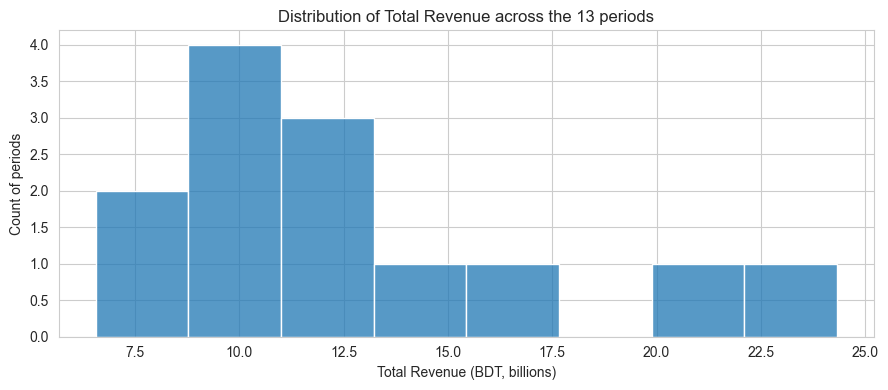

In [8]:
total_rev = df[df['line_item']=='Total Revenue'][years].iloc[0]
plt.figure(figsize=(9,4))
sns.histplot(total_rev.values/1e9, bins=8, kde=False)
plt.title("Distribution of Total Revenue across the 13 periods")
plt.xlabel("Total Revenue (BDT, billions)")
plt.ylabel("Count of periods")
plt.tight_layout(); plt.show()

### 3.6 Correlations
*Why:* Correlation across years tells us which line items move together - useful for identifying redundant drivers and for sanity-checking that revenue and cost lines co-vary as expected.

We restrict to rows fully populated for the actual years so the correlation is computed on a like-for-like basis.

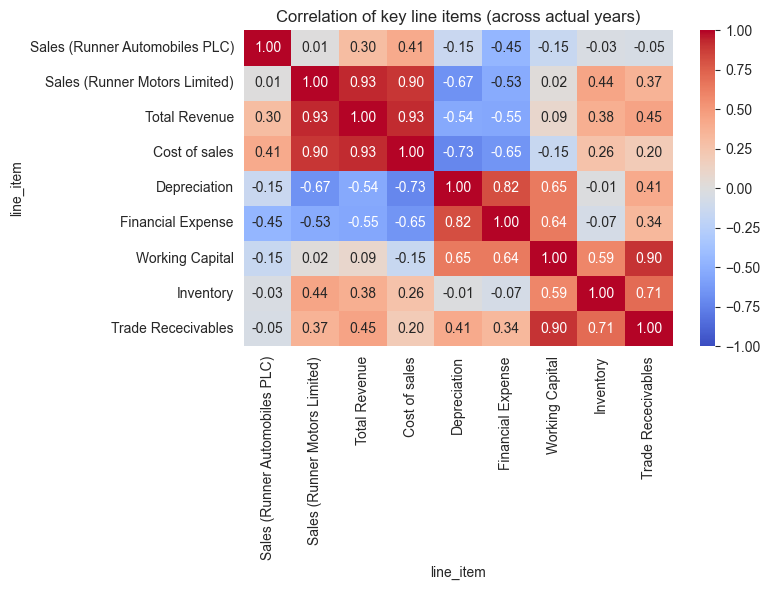

In [9]:
key_items = ['Total Revenue',
             'Sales (Runner Automobiles PLC)',
             'Sales (Runner Motors Limited)',
             'Cost of sales',
             'Financial Expense',
             'Depreciation',
             'Working Capital',
             'Inventory',
             'Trade Rececivables']

sub = df[df['line_item'].isin(key_items)].drop_duplicates('line_item').set_index('line_item')[actual_years]
corr = sub.T.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation of key line items (across actual years)")
plt.tight_layout(); plt.show()

### 3.7 Outlier detection
*Why:* In time-series financial data, an outlier is often a real event (COVID year, write-off, accounting restatement) rather than bad data - but flagging them still matters. We use the IQR rule on Total Revenue across all 13 periods.

In [10]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    return series[(series < lo) | (series > hi)]

tr = df[df['line_item']=='Total Revenue'][years].iloc[0]
print("Total Revenue outliers (1.5*IQR rule):")
print(iqr_outliers(tr))

Total Revenue outliers (1.5*IQR rule):
2029P    2.056981e+10
2030P    2.432848e+10
Name: 7, dtype: float64


## Task 4 - Data Visualisations

### 4.1 Total Revenue trajectory (Actual vs Projected)

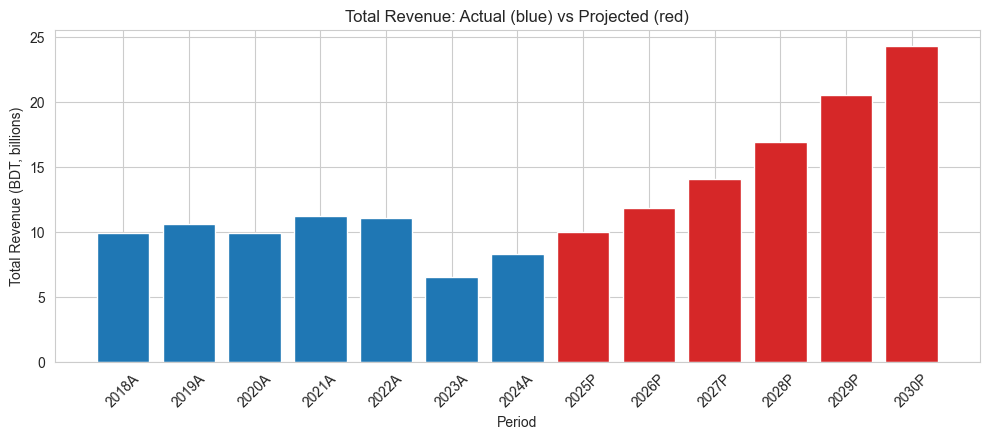

In [11]:
tr = df[df['line_item']=='Total Revenue'][years].iloc[0]
colors = ['#1f77b4' if y.endswith('A') else '#d62728' for y in years]

plt.figure(figsize=(10,4.5))
plt.bar(years, tr.values/1e9, color=colors)
plt.title("Total Revenue: Actual (blue) vs Projected (red)")
plt.xlabel("Period")
plt.ylabel("Total Revenue (BDT, billions)")
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

### 4.2 Revenue mix by entity - RAPLC vs RML

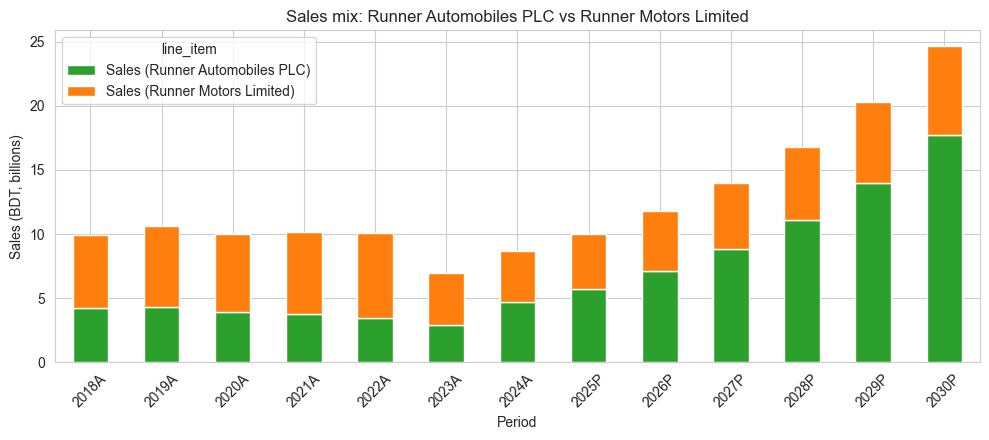

In [12]:
pick = ['Sales (Runner Automobiles PLC)', 'Sales (Runner Motors Limited)']
ent  = df[df['line_item'].isin(pick)].set_index('line_item')[years].T / 1e9

ax = ent.plot(kind='bar', stacked=True, figsize=(10,4.5),
              color=['#2ca02c','#ff7f0e'])
ax.set_title("Sales mix: Runner Automobiles PLC vs Runner Motors Limited")
ax.set_ylabel("Sales (BDT, billions)")
ax.set_xlabel("Period")
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

### 4.3 Cost of sales vs Total Revenue

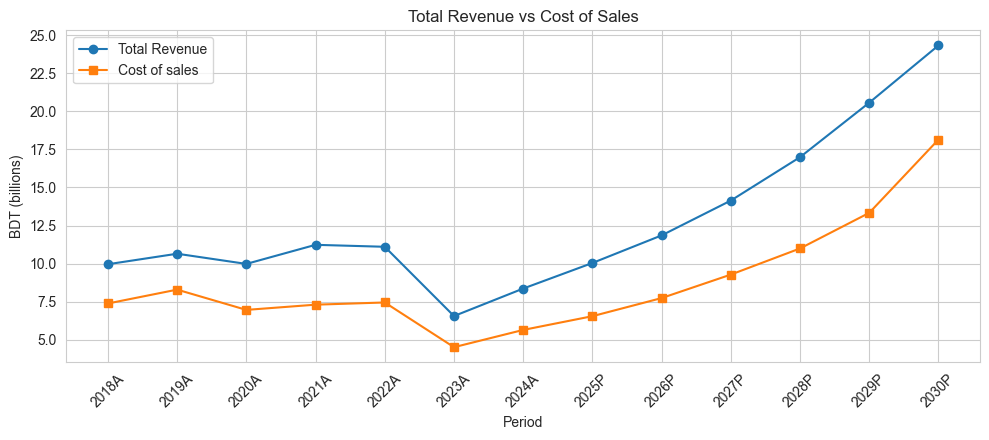

In [13]:
pick = ['Total Revenue','Cost of sales']
sub  = df[df['line_item'].isin(pick)].drop_duplicates('line_item').set_index('line_item')[years].T / 1e9

plt.figure(figsize=(10,4.5))
plt.plot(sub.index, sub['Total Revenue'], marker='o', label='Total Revenue')
plt.plot(sub.index, sub['Cost of sales'], marker='s', label='Cost of sales')
plt.title("Total Revenue vs Cost of Sales")
plt.xlabel("Period"); plt.ylabel("BDT (billions)")
plt.xticks(rotation=45); plt.legend()
plt.tight_layout(); plt.show()

### 4.4 Three-Wheelers share of RAPLC sales over time

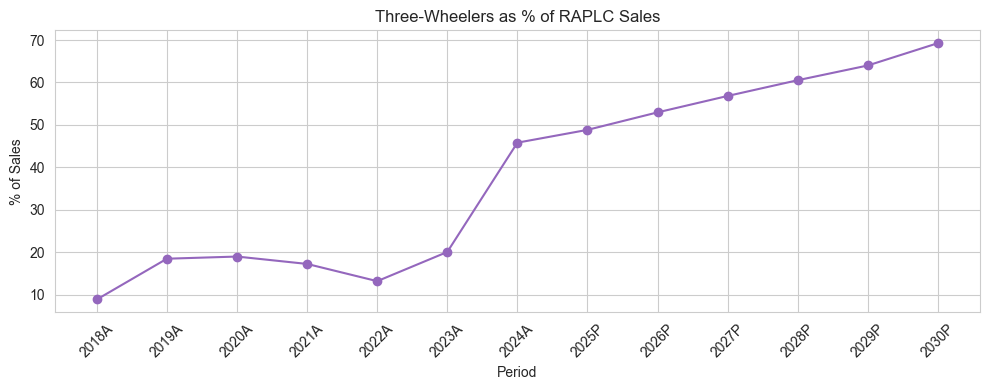

In [14]:
tw_idx = df[df['line_item']=='Three-Wheelers (BDT)'].index[0]
tw_share = df.iloc[tw_idx + 1][years].astype(float) * 100

plt.figure(figsize=(10,4))
plt.plot(years, tw_share.values, marker='o', color='#9467bd')
plt.title("Three-Wheelers as % of RAPLC Sales")
plt.xlabel("Period"); plt.ylabel("% of Sales")
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

### 4.5 Heat-map of motorcycle category revenue (RAPLC)

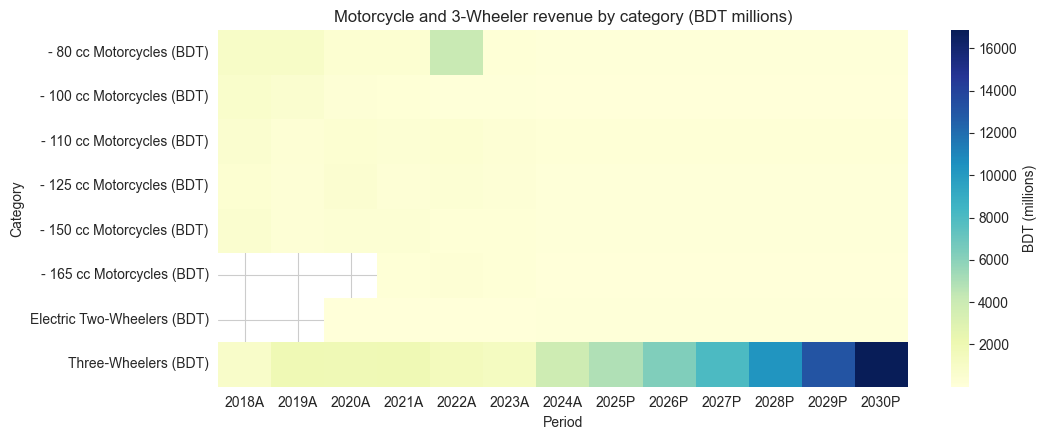

In [15]:
motor_items = ['- 80 cc Motorcycles (BDT)','- 100 cc Motorcycles (BDT)',
               '- 110 cc Motorcycles (BDT)','- 125 cc Motorcycles (BDT)',
               '- 150 cc Motorcycles (BDT)','- 165 cc Motorcycles (BDT)',
               'Electric Two-Wheelers (BDT)','Three-Wheelers (BDT)']
hm = df[df['line_item'].isin(motor_items)].set_index('line_item')[years] / 1e6

plt.figure(figsize=(11,4.5))
sns.heatmap(hm, cmap="YlGnBu", cbar_kws={'label':'BDT (millions)'})
plt.title("Motorcycle and 3-Wheeler revenue by category (BDT millions)")
plt.xlabel("Period"); plt.ylabel("Category")
plt.tight_layout(); plt.show()

### 4.6 Working capital and its components

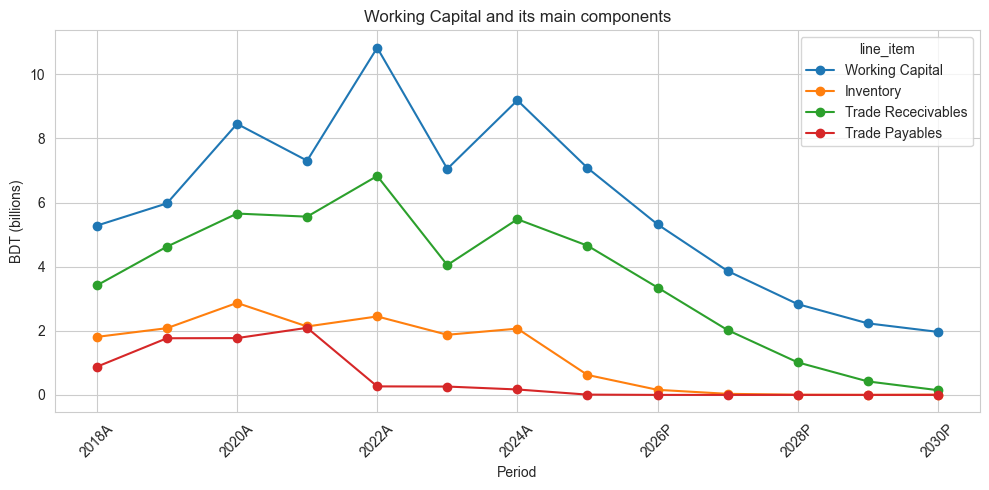

In [16]:
wc_items = ['Working Capital','Inventory','Trade Rececivables','Trade Payables']
wc = df[df['line_item'].isin(wc_items)].drop_duplicates('line_item').set_index('line_item')[years].T / 1e9

ax = wc.plot(figsize=(10,5), marker='o')
ax.set_title("Working Capital and its main components")
ax.set_xlabel("Period"); ax.set_ylabel("BDT (billions)")
plt.xticks(rotation=45)
plt.tight_layout(); plt.show()

### 4.7 Distribution of yearly Total Revenue (boxplot, Actual vs Projected)

C:\Users\Asir\AppData\Local\Temp\ipykernel_19992\1134158626.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tr_long, x='period_type', y='value_bn',


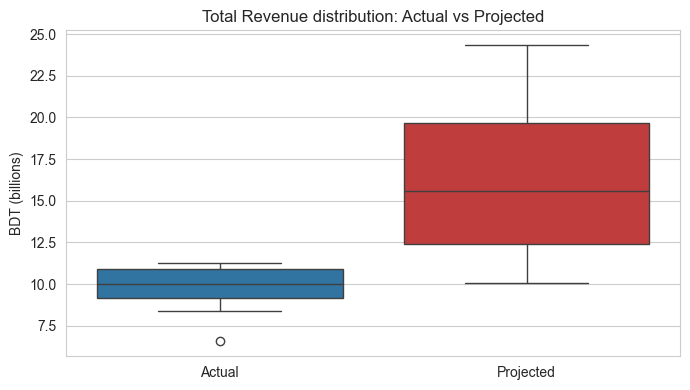

In [17]:
tr_long = long_df[long_df['line_item']=='Total Revenue'].dropna(subset=['value']).copy()
tr_long['value_bn'] = tr_long['value']/1e9
plt.figure(figsize=(7,4))
sns.boxplot(data=tr_long, x='period_type', y='value_bn',
            palette=['#1f77b4','#d62728'])
plt.title("Total Revenue distribution: Actual vs Projected")
plt.ylabel("BDT (billions)"); plt.xlabel("")
plt.tight_layout(); plt.show()

## Task 5 - Insights from the Visualisations

**1. Revenue trajectory (Fig 4.1).** Total revenue was broadly flat between 2018A and 2021A (BDT ~10-11 bn), then collapsed in **2023A** to BDT ~6.6 bn - a clear outlier confirmed by the IQR check in section 3.7 and visible as a deep dip in the bar chart. From 2024A onward the forecast is for a steep recovery, with revenue projected to more than double by 2030P. The 2030P figure is a tail forecast and should be stress-tested.

**2. Entity mix (Fig 4.2).** Before 2023, **Runner Motors Limited (RML)** contributed more than half of group sales. The forecast inverts this: by 2030P **Runner Automobiles PLC (RAPLC)** is expected to dominate the mix. The growth story is therefore an RAPLC story; RML is forecast to be roughly flat.

**3. Revenue vs Cost of Sales (Fig 4.3).** The two lines move in lock-step in the actuals (high correlation observed in section 3.6), but the projection widens the gap - i.e. management forecasts material operating-leverage expansion. This is a key sensitivity to challenge.

**4. Segment shift to Three-Wheelers (Fig 4.4).** Three-wheelers were ~9% of RAPLC sales in 2018A and are projected to be **~69% by 2030P**. This is the single biggest mix change in the model. Conventional motorcycle categories (80-150 cc) are projected to shrink as a share of sales (Fig 4.5).

**5. Heat-map (Fig 4.5).** The heat-map confirms two patterns: (a) motorcycle revenue is decaying across cubic-capacity buckets, and (b) Three-Wheelers light up the right-hand side, dominating the forecast period. Electric two-wheelers appear from 2020A onward and grow off a very small base.

**6. Working capital (Fig 4.6).** Working capital peaked in 2022A at BDT ~10.8 bn and is projected to **fall sharply** through to 2030P (down to ~BDT 2 bn). This is driven mainly by a forecast unwind in inventory and receivables - another aggressive assumption worth challenging.

**7. Actual vs Projected distribution (Fig 4.7).** The boxplot shows projected revenue has a much higher median and a wider spread, reflecting compounding growth in the forecast period. The 2023A collapse sits as a low-side outlier on the Actual side.

**8. Missingness pattern (section 3.1).** Missing values are concentrated in the **earliest actual years**: many sub-line items only appear from 2023A onward. This reflects increased reporting granularity rather than data corruption - imputation here would be inappropriate.

**Overall takeaway.** The dataset tells a clear two-act story: a COVID-era / 2023 trough in actuals, followed by an aggressive recovery scenario built on a pronounced shift toward three-wheelers and an unwind of working capital. The actuals are reliable; the projections embed strong assumptions that an analyst should pressure-test individually.